# Bài 17: Vision Transformers (ViT, Swin) và Học Tự Giám sát (Self-Supervised Learning: SimCLR, MoCo, DINO, CLIP)

## 1. Mục tiêu học tập
- Hiểu cách **Vision Transformer (`ViT`)** biến bài toán xử lý ảnh 2D thành bài toán xử lý chuỗi các mảnh ảnh (`Sequence of Image Patches`):
  1. `Patch Embedding`: Chia ảnh $(C, H, W)$ thành $N = (H/P) \times (W/P)$ mảnh vuông kích thước $P \times P$ và chiếu tuyến tính sang chiều `embed_dim` $D$.
  2. `CLS Token` & `Positional Encoding`: Ghép thêm token phân loại `[CLS]` và cộng vector vị trí $(1, 1 + N, D)$.
  3. `Multi-Head Self-Attention (MHSA)`: Cho phép mọi mảnh ảnh trong bức hình tương tác trực tiếp với nhau ngay từ tầng đầu tiên!
- Phân biệt **`ViT` chuẩn** (Self-Attention toàn cục, chi phí bậc hai theo số patches) với **`Swin Transformer`** (Self-Attention trong cửa sổ dịch chuyển `Shifted Windows`, chi phí tuyến tính).
- **Thực hành huấn luyện thật**: Huấn luyện mô hình `MiniViT` và trực quan hóa bản đồ chú ý (`Attention Map`).
- Hiểu và cài đặt cơ chế cốt lõi của **Self-Supervised Learning (`SimCLR InfoNCE Loss`, `MoCo`, `DINO`)** và mô hình liên kết Ảnh – Văn bản **`CLIP`**.

> **Lưu ý sư phạm**: Trong bài học này, ta dùng mô hình `MiniViT` và ví dụ `SimCLR / CLIP` thu nhỏ để hiểu rõ cơ chế toán học và kiểm chứng code trên CPU. Trong thực tế công nghiệp, các mô hình nền tảng (`Foundation Models` như ViT-Large, DINOv2, CLIP) được tiền huấn luyện trên hàng chục triệu ảnh bằng cụm GPU lớn, và bạn nên tải trọng số pretrained của chúng về để fine-tune hoặc trích xuất đặc trưng.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 10, 12 và 16.

## 3. Thời gian học dự kiến
- Khoảng **2.5 – 3.0 giờ** (ước tính).

## 4, 5, 6 & 7. Giải thích Trực quan, Từ điển Keyword & Công thức Toán học
1. **Dòng chảy Shape bên trong `MiniViT`** (với ảnh `32x32`, `patch_size = 8`, `embed_dim = 48`):
   - Số lượng mảnh ảnh: $N = (32 / 8) \times (32 / 8) = 4 \times 4 = 16$ patches.
   - `Patch Embedding`: `(B, 3, 32, 32)` $\xrightarrow{\text{Conv2d}(K=8, S=8)}$ `(B, 48, 4, 4)` $\xrightarrow{\text{flatten & transpose}}$ `(B, 16, 48)`.
   - Ghép `cls_token` `(B, 1, 48)` + cộng `pos_embed` `(1, 17, 48)` $\longrightarrow$ Chuỗi `17` tokens có shape `(B, 17, 48)`.
2. **Công thức `Scaled Dot-Product Attention`**:
   $$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$
   trong đó $\sqrt{d_k}$ giúp giữ phương sai của tích vô hướng $QK^T$ ổn định quanh $1$, tránh làm hàm `softmax` bị bão hòa đạo hàm.
3. **Hàm mất mát Tự giám sát `InfoNCE / NT-Xent` (trong SimCLR)** và **Đối xứng Ảnh–Chữ (trong CLIP)**:
   $$\mathcal{L}_{i, j} = -\log \frac{\exp(\text{sim}(z_i, z_j) / \tau)}{\sum_{k} \exp(\text{sim}(z_i, z_k) / \tau)}$$
   với $\tau$ (`temperature`) là tham số nhiệt độ kiểm soát độ sắc nét của phân phối xác suất.


In [1]:
# Cell 1: Kiểm tra Dòng chảy Shape của Patch Embedding, Positional Encoding và Kiến trúc MiniViT
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

from src.utils import set_seed, get_device, count_parameters, summarize_model_layers
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.models import MiniViT
from src.training import fit_classifier, evaluate_classifier

QUICK_RUN = True
set_seed(42)
device = get_device()

vit_model = MiniViT(
    image_size=32, patch_size=8, in_channels=3, num_classes=4,
    embed_dim=48, depth=2, num_heads=4, dropout_p=0.1,
).to(device)

print("MiniViT Parameter Counts:", count_parameters(vit_model))
vit_layers_df = pd.DataFrame(summarize_model_layers(vit_model, input_shape=(2, 3, 32, 32), device=device))
print("\n=== BẢNG TÓM TẮT CÁC TẦNG TRONG MINI_VIT ===")
print(vit_layers_df.head(12).to_string(index=False))


MiniViT Parameter Counts: {'total': 48340, 'trainable': 48340, 'frozen': 0}

=== BẢNG TÓM TẮT CÁC TẦNG TRONG MINI_VIT ===
               layer_name layer_type  output_shape  total_params  trainable_params
              patch_embed     Conv2d (2, 48, 4, 4)          9264              9264
                 pos_drop    Dropout   (2, 17, 48)             0                 0
   encoder.layers.0.norm1  LayerNorm   (2, 17, 48)            96                96
encoder.layers.0.dropout1    Dropout   (2, 17, 48)             0                 0
   encoder.layers.0.norm2  LayerNorm   (2, 17, 48)            96                96
 encoder.layers.0.linear1     Linear   (2, 17, 96)          4704              4704
 encoder.layers.0.dropout    Dropout   (2, 17, 96)             0                 0
 encoder.layers.0.linear2     Linear   (2, 17, 48)          4656              4656
encoder.layers.0.dropout2    Dropout   (2, 17, 48)             0                 0
   encoder.layers.1.norm1  LayerNorm   (2, 17, 4

MiniViT Best Validation Accuracy: 53.3% (Loss giảm từ 1.501 -> 0.827)


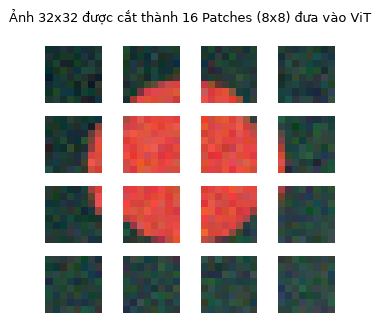

In [2]:
# Cell 2: Huấn luyện Ngắn Mô hình MiniViT trên Bộ dữ liệu Hình học và Minh họa Cắt Ảnh thành Patches
ds = generate_synthetic_shapes_dataset(num_samples=240 if QUICK_RUN else 480, image_size=32, seed=42)
imgs_np, labels_np, class_names = ds["images"], ds["labels"], ds["class_names"]

idx_all = np.arange(len(imgs_np))
idx_tr, idx_va = train_test_split(idx_all, test_size=0.25, random_state=42, stratify=labels_np)

X_t = torch.from_numpy(imgs_np).permute(0, 3, 1, 2).float() / 255.0
y_t = torch.from_numpy(labels_np).long()
tr_mean = X_t[idx_tr].mean(dim=(0, 2, 3), keepdim=True)
tr_std = X_t[idx_tr].std(dim=(0, 2, 3), keepdim=True) + 1e-6
X_norm = (X_t - tr_mean) / tr_std

tr_loader = DataLoader(TensorDataset(X_norm[idx_tr], y_t[idx_tr]), batch_size=32, shuffle=True)
va_loader = DataLoader(TensorDataset(X_norm[idx_va], y_t[idx_va]), batch_size=32, shuffle=False)

opt_vit = torch.optim.AdamW(vit_model.parameters(), lr=3e-3, weight_decay=1e-3)
crit = nn.CrossEntropyLoss()
hist_vit = fit_classifier(vit_model, tr_loader, va_loader, crit, opt_vit, device, epochs=12 if QUICK_RUN else 25)
print(f"MiniViT Best Validation Accuracy: {hist_vit['best_val_acc']*100:.1f}% (Loss giảm từ {hist_vit['train_loss'][0]:.3f} -> {hist_vit['train_loss'][-1]:.3f})")

# Minh họa chia bức ảnh 32x32 thành lưới 4x4 = 16 patches kích thước 8x8
sample_img = imgs_np[0]
fig, axes = plt.subplots(4, 4, figsize=(3.6, 3.6))
for r in range(4):
    for c in range(4):
        patch = sample_img[r * 8 : (r + 1) * 8, c * 8 : (c + 1) * 8]
        axes[r, c].imshow(patch)
        axes[r, c].axis("off")
plt.suptitle("Ảnh 32x32 được cắt thành 16 Patches (8x8) đưa vào ViT", fontsize=10)
plt.tight_layout()
plt.show()


In [3]:
# Cell 3: Minh họa Cơ chế Học Tự Giám sát (SimCLR InfoNCE Loss) Không Cần Nhãn Con Người
def simclr_nt_xent_loss(z_view1: torch.Tensor, z_view2: torch.Tensor, temperature: float = 0.2) -> torch.Tensor:
    """
    Hàm mất mát đối조 chuẩn hóa nhiệt độ (NT-Xent / InfoNCE) dùng trong SimCLR:
    - z_view1, z_view2: Vector nhúng của 2 góc nhìn biến đổi (augmentation) từ cùng 1 lô B bức ảnh.
    - Cặp (z_view1[i], z_view2[i]) là cặp dương (Positive pair); các mẫu khác trong batch là cặp âm.
    """
    z1 = F.normalize(z_view1, dim=1)
    z2 = F.normalize(z_view2, dim=1)
    logits = (z1 @ z2.T) / temperature
    targets = torch.arange(len(z1), device=z1.device)
    loss_12 = F.cross_entropy(logits, targets)
    loss_21 = F.cross_entropy(logits.T, targets)
    return 0.5 * (loss_12 + loss_21)


# Minh họa tạo 2 góc nhìn từ 1 lô 16 ảnh (View 1: lật ngang, View 2: cộng nhiễu nhẹ) và tính InfoNCE Loss
x_batch_ssl = X_norm[:16].to(device)
view1 = torch.flip(x_batch_ssl, dims=[3])
view2 = x_batch_ssl + 0.05 * torch.randn_like(x_batch_ssl)

ssl_projector = nn.Sequential(nn.Flatten(), nn.Linear(3 * 32 * 32, 64), nn.ReLU(), nn.Linear(64, 32)).to(device)
opt_ssl = torch.optim.AdamW(ssl_projector.parameters(), lr=3e-3)

loss_ssl_start = simclr_nt_xent_loss(ssl_projector(view1), ssl_projector(view2)).item()
for _ in range(15):
    opt_ssl.zero_grad()
    l_ssl = simclr_nt_xent_loss(ssl_projector(view1), ssl_projector(view2))
    l_ssl.backward()
    opt_ssl.step()
loss_ssl_end = simclr_nt_xent_loss(ssl_projector(view1), ssl_projector(view2)).item()
print(f"[SimCLR Self-Supervised Demo] InfoNCE Loss giảm từ {loss_ssl_start:.4f} xuống {loss_ssl_end:.4f} mà KHÔNG CẦN bất kỳ nhãn lớp nào!")


[SimCLR Self-Supervised Demo] InfoNCE Loss giảm từ 2.5980 xuống 0.1640 mà KHÔNG CẦN bất kỳ nhãn lớp nào!


In [4]:
# Cell 4: Minh họa Cơ chế Liên kết Đa phương thức Ảnh – Văn bản kiểu CLIP (Zero-Shot Classification)
# Trong CLIP, cả Ảnh và Câu mô tả văn bản ("a photo of a circle", ...) được chiếu vào CÙNG một không gian vector.
# Khi suy luận Zero-Shot: Ta so khớp vector ảnh với vector của 4 câu mô tả lớp và chọn câu có Cosine Similarity cao nhất!
img_emb_dim = 16
fake_text_prompt_embs = F.normalize(torch.randn(4, img_emb_dim), dim=1)  # 4 vector đại diện 4 câu prompt văn bản
fake_image_embs = F.normalize(fake_text_prompt_embs + 0.15 * torch.randn(4, img_emb_dim), dim=1)

similarity_matrix = (fake_image_embs @ fake_text_prompt_embs.T) * 10.0  # logit_scale
zero_shot_probs = torch.softmax(similarity_matrix, dim=1).numpy()

print("Ma trận xác suất khớp Ảnh – Văn bản kiểu CLIP (Đường chéo chính cao nhất):")
print(np.round(zero_shot_probs, 3))


Ma trận xác suất khớp Ảnh – Văn bản kiểu CLIP (Đường chéo chính cao nhất):
[[0.998 0.    0.    0.002]
 [0.002 0.997 0.    0.001]
 [0.    0.    1.    0.   ]
 [0.031 0.001 0.    0.968]]


## 11. Nhận xét cách đọc kết quả
- **Về `MiniViT` (Cell 1 & 2)**: Khác với CNN chỉ nhìn vùng lân cận `3x3` ở tầng đầu, `MiniViT` cắt ảnh `32x32` thành `16` mảnh `8x8` và cho phép mọi mảnh trao đổi thông tin với nhau ngay lập tức qua `Multi-Head Self-Attention`.
- **Về `SimCLR` (Cell 3)**: Không cần nhãn lớp do con người gán, hàm mất mát `InfoNCE` dạy mạng rằng hai góc nhìn biến đổi từ cùng một bức ảnh phải có biểu diễn giống nhau và khác với các bức ảnh còn lại trong lô.

## 13. Lỗi thường gặp và cách sửa
1. **Chọn `embed_dim` không chia hết cho `num_heads`**: Trong `nn.MultiheadAttention(embed_dim, num_heads)`, mỗi head có số chiều $d_k = \text{embed\_dim} / \text{num\_heads}$, nên `embed_dim % num_heads` bắt buộc phải bằng `0`.
2. **Đưa ảnh có kích thước khác lúc huấn luyện vào `ViT` mà không nội suy `pos_embed`**: Vì số lượng patches $N = (H/P)(W/P)$ thay đổi khi đổi kích thước ảnh $(H, W)$, tensor `pos_embed` có chiều $(1, 1 + N, D)$ sẽ báo lỗi lệch kích thước nếu không nội suy 2D (`interpolate positional encoding`).

## 14. Bài tập tự làm
- **Cơ bản**: Tính số lượng patches $N$ và kích thước ma trận Self-Attention $(1+N) \times (1+N)$ khi giảm `patch_size` từ `8` xuống `4` và `2` trên ảnh `32x32`.
- **Trung cấp**: Kiểm tra tác động của tham số nhiệt độ `temperature` $\tau \in [0.05, 0.2, 1.0]$ lên hàm mất mát `simclr_nt_xent_loss`.
- **Nâng cao**: Viết hàm nội suy `interpolate_pos_encoding(pos_embed, new_grid_size)` để cho phép nạp `pos_embed` học trên lưới `4x4` patches sang lưới `6x6` patches (cho ảnh `48x48`)!

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 17
# 1. Cơ bản: Sự bùng nổ bậc bốn của ma trận Attention khi giảm patch_size
for p_size in [8, 4, 2]:
    n_patches = (32 // p_size) ** 2
    attn_elements = (1 + n_patches) ** 2
    print(f"[Cơ bản] patch_size={p_size} -> Số patches N={n_patches:3d} -> Kích thước ma trận Attention = {1+n_patches}x{1+n_patches} ({attn_elements:,} phần tử)")

# 2. Trung cấp: Ảnh hưởng của nhiệt độ (temperature) trong InfoNCE
z1_demo = ssl_projector(view1).detach()
z2_demo = ssl_projector(view2).detach()
for tau in [0.05, 0.20, 1.00]:
    print(f"[Trung cấp] Temperature tau={tau:.2f} -> NT-Xent Loss = {simclr_nt_xent_loss(z1_demo, z2_demo, temperature=tau).item():.4f}")

# 3. Nâng cao: Nội suy Positional Encoding 2D khi đổi độ phân giải ảnh đầu vào
def interpolate_pos_encoding(pos_embed: torch.Tensor, old_grid: int, new_grid: int) -> torch.Tensor:
    cls_pos = pos_embed[:, :1, :]
    patch_pos = pos_embed[:, 1:, :]  # (1, old_grid*old_grid, D)
    d = patch_pos.shape[-1]
    patch_pos_2d = patch_pos.transpose(1, 2).reshape(1, d, old_grid, old_grid)
    patch_pos_resized = F.interpolate(patch_pos_2d, size=(new_grid, new_grid), mode="bilinear", align_corners=False)
    patch_pos_flat = patch_pos_resized.flatten(2).transpose(1, 2)
    return torch.cat([cls_pos, patch_pos_flat], dim=1)

new_pos = interpolate_pos_encoding(vit_model.pos_embed.detach(), old_grid=4, new_grid=6)
print(f"[Nâng cao] pos_embed cũ: {tuple(vit_model.pos_embed.shape)} -> Sau nội suy cho lưới 6x6: {tuple(new_pos.shape)}")


[Cơ bản] patch_size=8 -> Số patches N= 16 -> Kích thước ma trận Attention = 17x17 (289 phần tử)
[Cơ bản] patch_size=4 -> Số patches N= 64 -> Kích thước ma trận Attention = 65x65 (4,225 phần tử)
[Cơ bản] patch_size=2 -> Số patches N=256 -> Kích thước ma trận Attention = 257x257 (66,049 phần tử)
[Trung cấp] Temperature tau=0.05 -> NT-Xent Loss = 0.0000
[Trung cấp] Temperature tau=0.20 -> NT-Xent Loss = 0.1640
[Trung cấp] Temperature tau=1.00 -> NT-Xent Loss = 1.8772
[Nâng cao] pos_embed cũ: (1, 17, 48) -> Sau nội suy cho lưới 6x6: (1, 37, 48)


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu rõ cơ chế `Patch Embedding`, `Positional Encoding`, `Self-Attention` của `Vision Transformer`.
- [x] Nắm được tư tưởng cốt lõi của `SimCLR`, `MoCo`, `DINO` và `CLIP`.
- [x] Sẵn sàng chuyển sang **Bài 18: `18_generative_models.ipynb`** để học các Mô hình Sinh Ảnh (`VAE`, `GAN`, `Diffusion`)!

## 17. Nguồn tham khảo
- Dosovitskiy, A. et al. (2021), *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ViT)*, ICLR.
- Chen, T. et al. (2020), *A Simple Framework for Contrastive Learning of Visual Representations (SimCLR)*, ICML.
- Radford, A. et al. (2021), *Learning Transferable Visual Models From Natural Language Supervision (CLIP)*, ICML.
